# Day 5: Anomaly Detection with Anomalib and PatchCore

Goal: understand anomaly detection for industrial defects, create a small MVTec-style folder dataset, train PatchCore using only normal images, and inspect anomaly scores and heatmaps.

Anomaly detection is different from ordinary classification: the model learns what normal examples look like, then flags unusual samples or regions.

For a reliable, lightweight Colab exercise, this notebook creates a small **synthetic MVTec-style dataset** with normal and defective texture images. It uses the same normal/train and good/bad test folder idea as industrial anomaly datasets.

Install Anomalib

In [1]:
!pip -q install anomalib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Imports and environment

In [2]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


What is anomaly detection?

In industrial inspection, most training images may show a normal product, while defective examples are rare or varied.

- **Normal samples:** examples of acceptable products or surfaces.
- **Anomalies:** defects such as scratches, dents, contamination, cracks or unexpected texture changes.
- **Anomaly score:** a score indicating how unusual an image is.
- **Anomaly map:** a pixel-level heatmap showing where unusual patterns may be located.

Two common approaches:

- **Reconstruction methods (autoencoders):** learn to reconstruct normal images. Defects may have larger reconstruction errors.
- **Embedding-distance methods (PatchCore / PaDiM):** extract features from pretrained networks and model the distribution of normal feature patches. Patches that are far from normal features receive higher anomaly scores.

We will use PatchCore through Anomalib.

Create a small MVTec-style dataset

In [3]:
# We create simple textured images so this notebook can run without
# downloading the full multi-gigabyte MVTec AD dataset.
# Folder layout follows the normal/train and good/bad test convention.

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("synthetic_mvtec_style")
for folder in [
    DATA_ROOT / "train" / "good",
    DATA_ROOT / "test" / "good",
    DATA_ROOT / "test" / "bad"
]:
    folder.mkdir(parents=True, exist_ok=True)

def make_normal_texture(seed, size=256):
    rng = np.random.default_rng(seed)
    base = np.zeros((size, size, 3), dtype=np.uint8)
    x = np.linspace(0, 1, size)
    for row in range(size):
        shade = 150 + int(25 * np.sin(row / 13))
        noise = rng.normal(0, 5, size)
        base[row, :, 0] = np.clip(shade + noise, 0, 255)
        base[row, :, 1] = np.clip(shade + 12 + noise, 0, 255)
        base[row, :, 2] = np.clip(shade + 20 + noise, 0, 255)
    image = Image.fromarray(base)
    draw = ImageDraw.Draw(image)
    # Repeated fine lines create a simple manufactured-surface texture.
    for x_pos in range(0, size, 16):
        draw.line((x_pos, 0, x_pos, size), fill=(135, 150, 165), width=1)
    return image

def add_defect(image, seed):
    rng = random.Random(seed)
    image = image.copy()
    draw = ImageDraw.Draw(image)
    # Add a visible scratch-like or stain-like abnormal region.
    if seed % 2 == 0:
        x1, y1 = rng.randint(30, 150), rng.randint(30, 150)
        x2, y2 = x1 + rng.randint(35, 85), y1 + rng.randint(5, 25)
        draw.line((x1, y1, x2, y2), fill=(35, 25, 20), width=7)
    else:
        x, y = rng.randint(45, 190), rng.randint(45, 190)
        radius = rng.randint(12, 25)
        draw.ellipse((x-radius, y-radius, x+radius, y+radius),
                     fill=(55, 45, 40))
    return image

# Normal training images only.
for i in range(40):
    make_normal_texture(SEED + i).save(DATA_ROOT / "train" / "good" / f"normal_{i:03d}.png")

# Normal and defective test images.
for i in range(10):
    make_normal_texture(1000 + i).save(DATA_ROOT / "test" / "good" / f"good_{i:03d}.png")

for i in range(10):
    normal = make_normal_texture(2000 + i)
    add_defect(normal, i).save(DATA_ROOT / "test" / "bad" / f"defect_{i:03d}.png")

print("Training normal images:", len(list((DATA_ROOT / "train" / "good").glob("*.png"))))
print("Test normal images:", len(list((DATA_ROOT / "test" / "good").glob("*.png"))))
print("Test defective images:", len(list((DATA_ROOT / "test" / "bad").glob("*.png"))))

Training normal images: 40
Test normal images: 10
Test defective images: 10


Visualize normal and defective examples

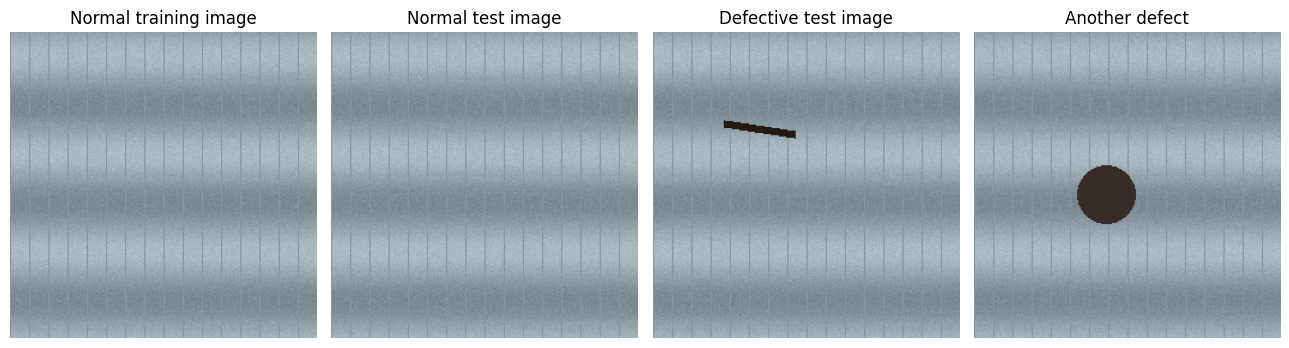

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
examples = [
    next((DATA_ROOT / "train" / "good").glob("*.png")),
    next((DATA_ROOT / "test" / "good").glob("*.png")),
    next((DATA_ROOT / "test" / "bad").glob("*.png")),
    list((DATA_ROOT / "test" / "bad").glob("*.png"))[1]
]
titles = ["Normal training image", "Normal test image", "Defective test image", "Another defect"]
for ax, path, title in zip(axes, examples, titles):
    ax.imshow(Image.open(path))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

Load the Anomalib Folder datamodule

Anomalib's `Folder` datamodule reads normal training images and separates normal and anomalous test images. The directory names are passed explicitly below.

In [5]:
from anomalib.data import Folder
from anomalib.models import Patchcore
from anomalib.engine import Engine

datamodule = Folder(
    name="synthetic_mvtec_style",
    root=DATA_ROOT,
    normal_dir="train/good",
    abnormal_dir="test/bad",
    normal_test_dir="test/good",
    train_batch_size=8,
    eval_batch_size=8,
    num_workers=2
)

datamodule.setup()
print("Anomalib Folder datamodule is ready.")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Anomalib Folder datamodule is ready.


Train PatchCore

In [6]:
import logging

logging.getLogger("anomalib").setLevel(logging.ERROR)

model = Patchcore()

engine = Engine(
    max_epochs=1,
    accelerator="auto",
    devices=1,
    enable_progress_bar=False,
    enable_model_summary=False
)

engine.fit(model=model, datamodule=datamodule)

print("PatchCore training / memory-bank setup finished.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/lo

PatchCore training / memory-bank setup finished.


In [7]:
print("Model:", model)
print("Datamodule:", datamodule)
print("Training check completed.")

Model: Patchcore(
  (pre_processor): PreProcessor(
    (transform): Compose(
          Resize(size=[256, 256], interpolation=bilinear, antialias=True)
          Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
    )
    (export_transform): Compose(
          Resize(size=[256, 256], interpolation=bilinear, antialias=False)
          Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
    )
  )
  (post_processor): PostProcessor(
    (_image_threshold_metric): F1AdaptiveThreshold()
    (_pixel_threshold_metric): F1AdaptiveThreshold()
    (_image_min_max_metric): MinMax()
    (_pixel_min_max_metric): MinMax()
  )
  (evaluator): Evaluator(
    (val_metrics): ModuleList()
    (test_metrics): ModuleList(
      (0): AUROC()
      (1): F1Score()
      (2): AUROC()
      (3): F1Score()
    )
  )
  (model): PatchcoreModel(
    (feature_extractor): TimmFeatureExtractor(
      (feature_extractor): FeatureListNet(
        (conv1): Conv2d(3, 

In [8]:
print("Model memory bank:", hasattr(model, "memory_bank"))
print("Training status check complete.")

Model memory bank: False
Training status check complete.


Evaluate on normal and defective test images

In [9]:
test_metrics = engine.test(model=model, datamodule=datamodule)
print(test_metrics)

INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric AUROC was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric F1Score was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │            1.0            │
│       image_F1Score       │            1.0            │
└───────────────────────────┴───────────────────────────┘

[{'image_AUROC': 1.0, 'image_F1Score': 1.0}]


Run prediction and inspect anomaly maps

In [10]:
# Anomalib returns prediction batches containing anomaly scores and maps.
predictions = engine.predict(model=model, datamodule=datamodule)

print("Prediction batches:", len(predictions) if predictions is not None else 0)
if predictions:
    first_batch = predictions[0]
    print("Prediction output type:", type(first_batch))
    print("Available fields:", getattr(first_batch, "keys", lambda: [])())

INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Prediction batches: 2
Prediction output type: <class 'anomalib.data.dataclasses.torch.image.ImageBatch'>
Available fields: ['image', 'gt_label', 'gt_mask', 'mask_path', 'anomaly_map', 'pred_score', 'pred_mask', 'pred_label', 'explanation', 'image_path']


Visualize prediction results

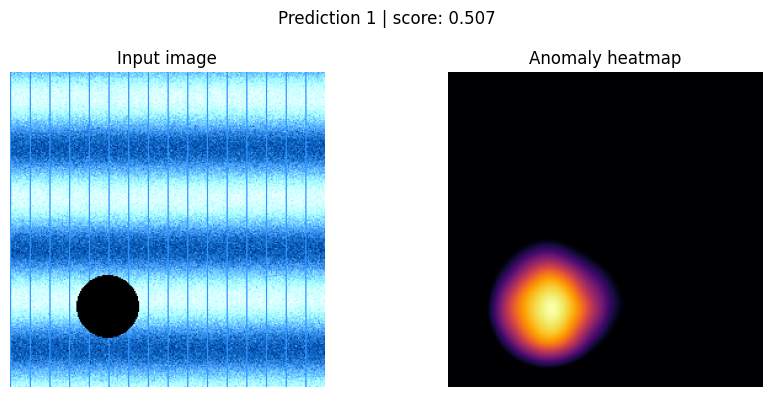

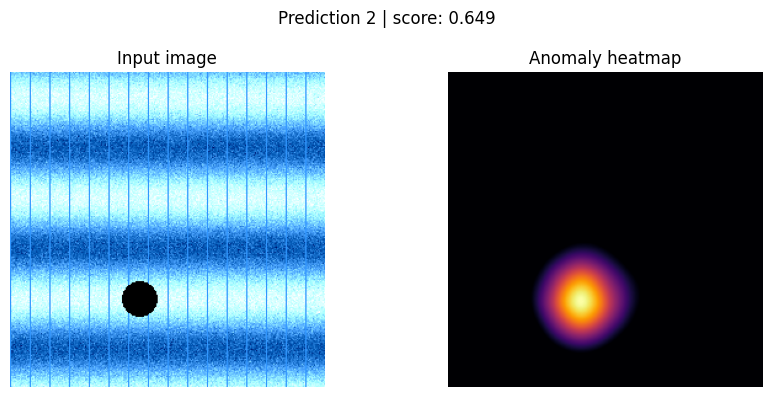

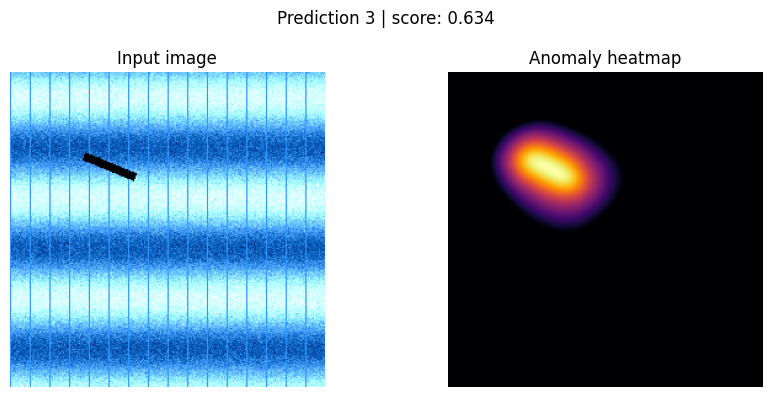

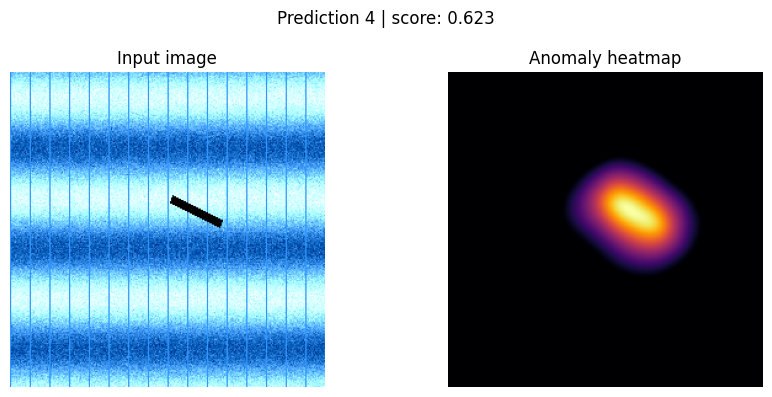

In [11]:
# This cell handles the standard Anomalib prediction batch output.
# It displays the input image and anomaly map for a few samples.
def get_field(batch, field):
    if isinstance(batch, dict):
        return batch.get(field)
    return getattr(batch, field, None)

shown = 0
if predictions:
    for batch in predictions:
        images = get_field(batch, "image")
        anomaly_maps = get_field(batch, "anomaly_map")
        pred_scores = get_field(batch, "pred_score")
        paths = get_field(batch, "image_path")

        if images is None or anomaly_maps is None:
            continue

        images = images.detach().cpu()
        anomaly_maps = anomaly_maps.detach().cpu()
        batch_size = images.shape[0]

        for i in range(batch_size):
            image = images[i].permute(1, 2, 0).numpy()
            image = np.clip(image, 0, 1)
            anomaly_map = anomaly_maps[i].squeeze().numpy()

            fig, axes = plt.subplots(1, 2, figsize=(9, 4))
            axes[0].imshow(image)
            axes[0].set_title("Input image")
            axes[0].axis("off")
            axes[1].imshow(anomaly_map, cmap="inferno")
            axes[1].set_title("Anomaly heatmap")
            axes[1].axis("off")
            score_text = ""
            if pred_scores is not None:
                score_text = f" | score: {float(pred_scores[i]):.3f}"
            plt.suptitle(f"Prediction {shown + 1}{score_text}")
            plt.tight_layout()
            plt.show()

            shown += 1
            if shown >= 4:
                break
        if shown >= 4:
            break

if shown == 0:
    print("No prediction batches with image and anomaly_map fields were returned.")
    print("Use the printed prediction output fields to inspect the installed Anomalib version.")

Review what the anomaly map means

A bright region in the anomaly heatmap indicates a region the model considers less similar to the normal training examples. The exact colour scale is for visualization; interpret it together with the image-level anomaly score and the ground-truth normal/defect label.

This synthetic dataset is intentionally simple. Real defects vary in size, shape, material, lighting and location. A real industrial benchmark such as MVTec AD is needed for meaningful benchmark comparisons.